# **Projek Pembelajaran Mesin**

Judul: Deteksi Hoaks Berita Politik Indonesia Berbasis Text Mining dengan Perbandingan Metode Naive Bayes dan Support Vector Machine

Topik: Text Mining dan Klasifikasi Teks Berita Hoaks Menggunakan Machine Learning



Anggota Kelompok:

- Jeika Antama Syalom Tarigan (24031554011)
- Ayda' Nur Salzabillah             (24031554017)
- Gresya Maranatha Sihaloho    (24031554027)
- Muhammad Zikri Widiandra   (24031554088)

Kelompok 9

Kelas 2024 B

Dataset: https://www.kaggle.com/datasets/linkgish/indonesian-fact-and-hoax-political-news/data?select=RAW

# **1. IMPORT LIBRARY DAN LOAD DATASET**

## 1.1 Import Library

In [ ]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# NLP
import nltk
from nltk.tokenize import word_tokenize

# Sastrawi (Indonesian stemmer & stopword)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# WordCloud
from wordcloud import WordCloud

# Sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Imbalanced-learn
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')

# Download NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Matplotlib style
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

COLORS = {
    'fakta': '#2196F3',
    'hoaks': '#F44336',
    'primary': '#3F51B5',
    'secondary': '#FF9800',
    'bg': '#F5F5F5',
    'green': '#4CAF50',
    'purple': '#9C27B0',
}

OUTPUT_DIR = './output_figures'
os.makedirs(OUTPUT_DIR, exist_ok=True)
DATA_DIR = './data/raw'

## 1.2 Load Dataset Raw

In [ ]:
cnn    = pd.read_excel('dataset_cnn_10k.xlsx')
kompas = pd.read_excel('dataset_kompas_4k.xlsx')
tempo  = pd.read_excel('dataset_tempo_6k.xlsx')
hoaks  = pd.read_excel('dataset_turnbackhoax_10k.xlsx')

print("CNN :", cnn.shape)
print("Kompas :", kompas.shape)
print("Tempo :", tempo.shape)
print("TurnBackHoax :", hoaks.shape)

CNN : (10000, 6)
Kompas : (4750, 6)
Tempo : (6592, 6)
TurnBackHoax : (10384, 6)


# **2. MANUAL LABELLING**

CNN, Kompas, Tempo → Fakta (0)

TurnBackHoax → Hoaks (1)

In [ ]:
cnn['label'] = 0
kompas['label'] = 0
tempo['label'] = 0

hoaks['label'] = 1

print("Manual labelling berhasil!")

Manual labelling berhasil!


Menambahkan kolom sumber

In [ ]:
cnn['sumber'] = 'CNN Indonesia'
kompas['sumber'] = 'Kompas'
tempo['sumber'] = 'Tempo'
hoaks['sumber'] = 'TurnBackHoax'

# **3. PENGGABUNGAN DATASET**

In [ ]:
# PILIH KOLOM YANG DIGUNAKAN
kolom_teks = 'FullText'

cnn = cnn[[kolom_teks, 'label', 'sumber']]
kompas = kompas[[kolom_teks, 'label', 'sumber']]
tempo = tempo[[kolom_teks, 'label', 'sumber']]
hoaks = hoaks[[kolom_teks, 'label', 'sumber']]

# GABUNGKAN DATASET
df = pd.concat(
    [cnn, kompas, tempo, hoaks],
    ignore_index=True
)

print(f'Total data gabungan : {len(df)}')
df.head()

Total data gabungan : 31726


,FullText,label,sumber
0,"Jakarta, CNN Indonesia -- Mantan Gubernur DKI ...",0,CNN Indonesia
1,"Medan, CNN Indonesia -- Gubernur Sumatera Utar...",0,CNN Indonesia
2,"Jakarta, CNN Indonesia -- Partai Kebangkitan B...",0,CNN Indonesia
3,"Jakarta, CNN Indonesia -- Ketua Umum Partai Ke...",0,CNN Indonesia
4,"Jakarta, CNN Indonesia -- Dewan Pimpinan Pusat...",0,CNN Indonesia


# **4. EDA AWAL**

### 4.1 Distribusi Kelas (Fakta vs Hoaks)

=== DISTRIBUSI KELAS ===
Fakta: 21342 data (67.27%)
Hoaks: 10384 data (32.73%)


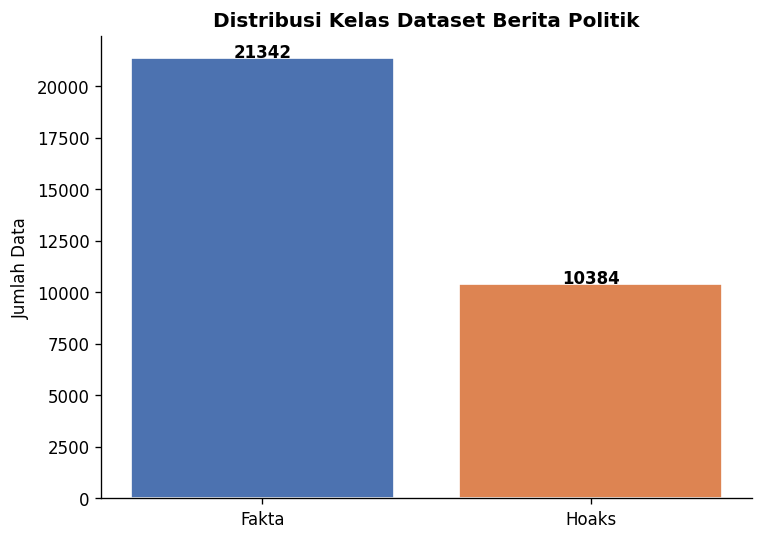


Dataset bersifat imbalance → akan ditangani menggunakan SMOTE.


In [ ]:
# Hitung distribusi kelas
dist_kelas = df['label'].value_counts()
label_names = {0: 'Fakta', 1: 'Hoaks'}

print('=== DISTRIBUSI KELAS ===')
for k, v in dist_kelas.items():
    print(f'{label_names[k]}: {v} data ({v/len(df)*100:.2f}%)')

# Visualisasi Bar Chart
plt.figure(figsize=(7,5))

colors = ['#4C72B0', '#DD8452']

bars = plt.bar(
    ['Fakta', 'Hoaks'],
    dist_kelas.values,
    color=colors,
    edgecolor='white'
)

plt.title('Distribusi Kelas Dataset Berita Politik', fontweight='bold')
plt.ylabel('Jumlah Data')

# Menampilkan jumlah data di atas batang
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 50,
        yval,
        ha='center',
        fontweight='bold'
    )

plt.show()

print("\nDataset bersifat imbalance → akan ditangani menggunakan SMOTE.")

### 4.2 Distribusi Sumber Berita

=== DISTRIBUSI SUMBER BERITA ===
sumber
TurnBackHoax     10384
CNN Indonesia    10000
Tempo             6592
Kompas            4750
Name: count, dtype: int64


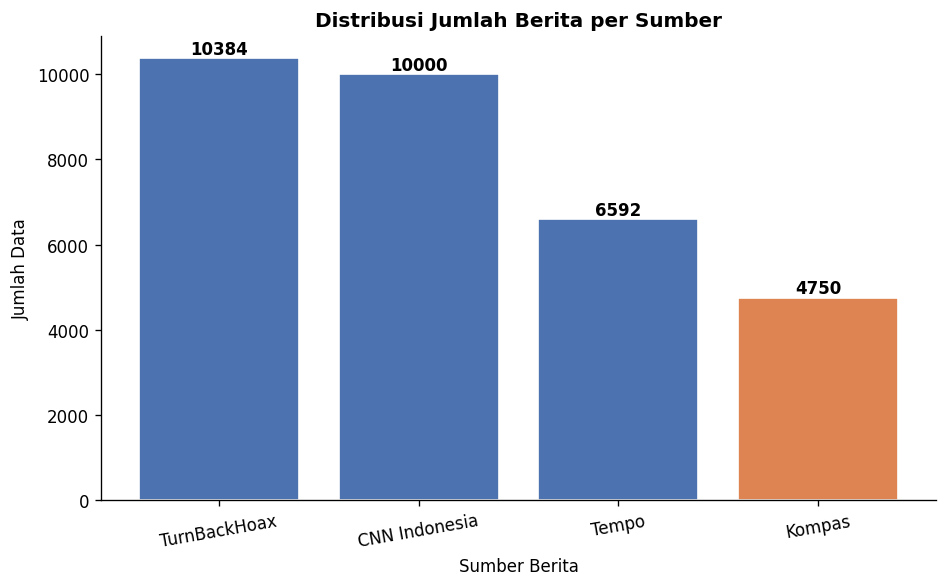

In [ ]:
# Distribusi jumlah berita per sumber
dist_sumber = df['sumber'].value_counts()

print('=== DISTRIBUSI SUMBER BERITA ===')
print(dist_sumber)

# Visualisasi bar chart
plt.figure(figsize=(8,5))

palette = ['#4C72B0', '#4C72B0', '#4C72B0', '#DD8452']

bars = plt.bar(
    dist_sumber.index,
    dist_sumber.values,
    color=palette,
    edgecolor='white'
)

# Judul dan label
plt.title('Distribusi Jumlah Berita per Sumber', fontweight='bold')
plt.xlabel('Sumber Berita')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=10)

# Menampilkan jumlah data di atas batang
for bar in bars:
    tinggi = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        tinggi + (max(dist_sumber.values) * 0.01),
        f'{int(tinggi)}',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('distribusi_sumber.png', dpi=150)
plt.show()

### 4.3 Analisis Panjang Teks

=== STATISTIK PANJANG TEKS ===
                 mean  min   max
Fakta (0)  330.945272    1  3472
Hoaks (1)  388.083975    1  5286


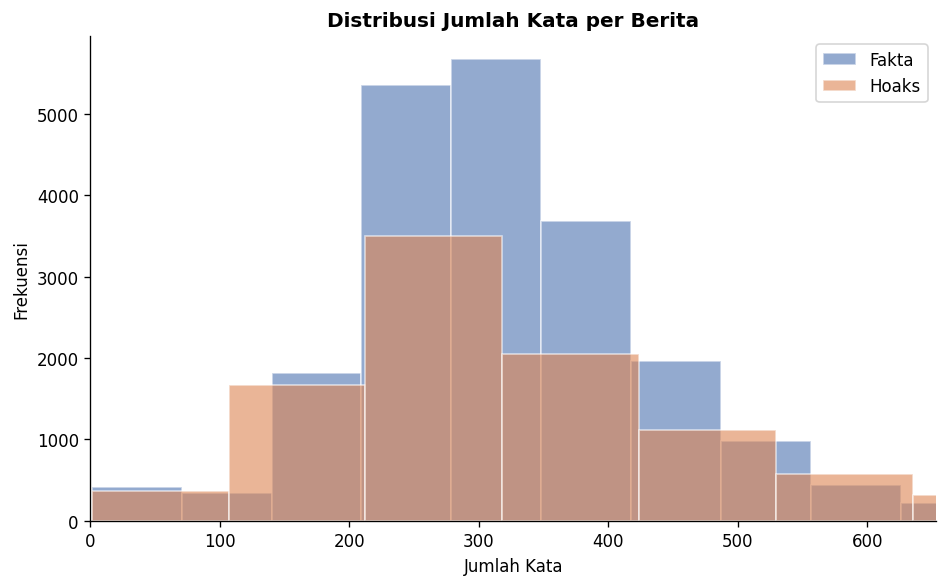

In [ ]:
# Hitung panjang teks (jumlah karakter dan kata)
kolom_teks = 'FullText'

df['jumlah_kata']      = df[kolom_teks].astype(str).apply(lambda x: len(x.split()))

# Statistik panjang teks per kelas
print('=== STATISTIK PANJANG TEKS ===')
stats = df.groupby('label')['jumlah_kata'].agg(['mean', 'min', 'max'])
stats.index = ['Fakta (0)', 'Hoaks (1)']
print(stats)

# Visualisasi distribusi jumlah kata
plt.figure(figsize=(8,5))

for label, color, name in [
    (0, '#4C72B0', 'Fakta'),
    (1, '#DD8452', 'Hoaks')
]:
    subset = df[df['label'] == label]['jumlah_kata']

    plt.hist(
        subset,
        bins=50,
        alpha=0.6,
        color=color,
        label=name,
        edgecolor='white'
    )

plt.title('Distribusi Jumlah Kata per Berita', fontweight='bold')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.legend()
plt.xlim(0, df['jumlah_kata'].quantile(0.95))
plt.tight_layout()
plt.savefig('panjang_teks.png', dpi=150)
plt.show()

Histogram menunjukkan bahwa distribusi jumlah kata pada berita fakta dan hoaks memiliki pola yang cukup mirip, dengan mayoritas berita berada pada rentang sekitar 200–400 kata. Namun, berita fakta cenderung lebih terkonsentrasi di sekitar 250–350 kata, sedangkan berita hoaks memiliki sebaran yang lebih luas hingga lebih dari 600 kata. Hal ini mengindikasikan bahwa berita hoaks cenderung lebih bervariasi panjangnya dibandingkan berita fakta.

### 4.4 Word Cloud Teks Mentah (Sebelum Pre-Processing)

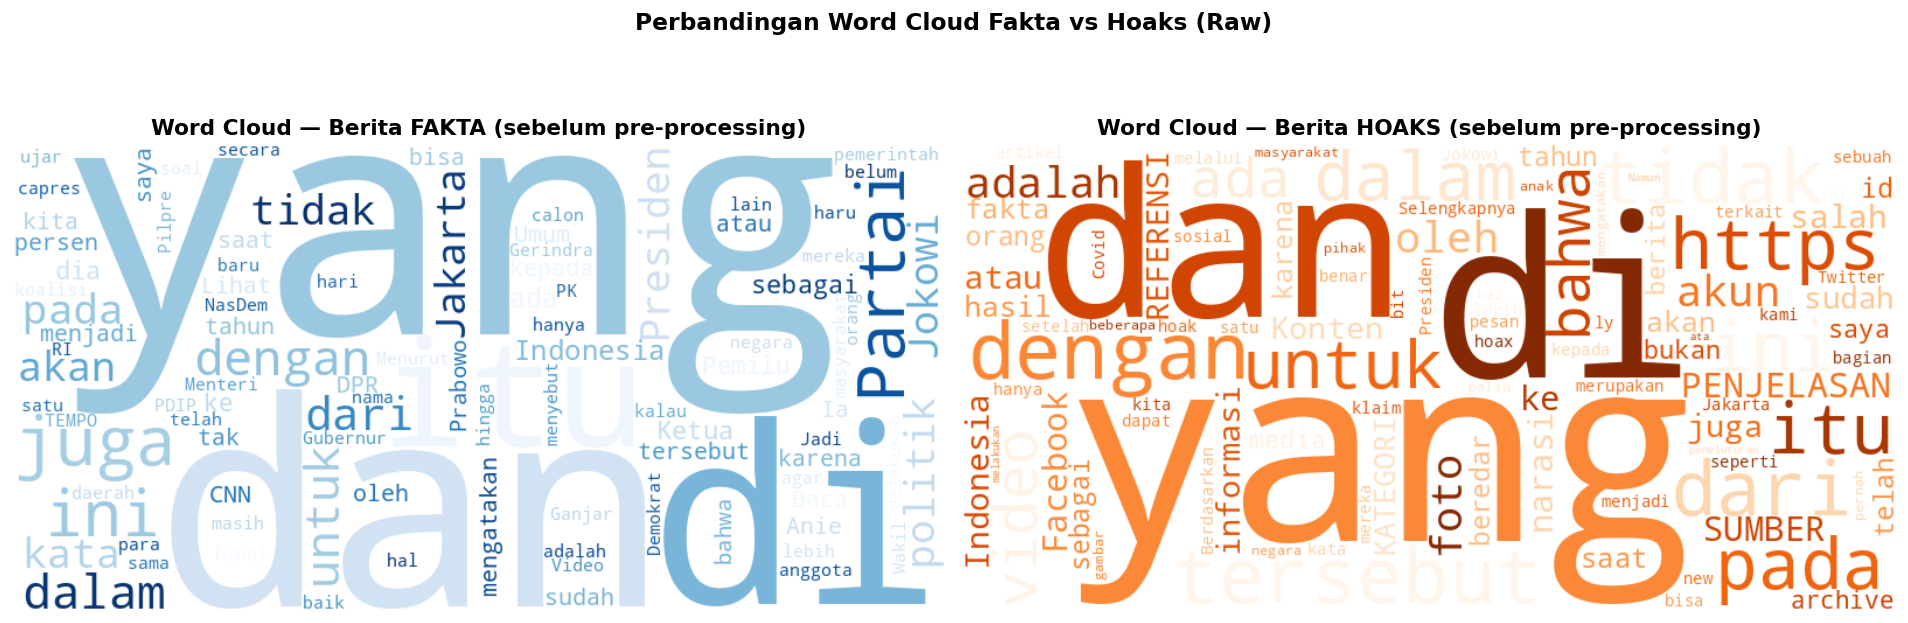

In [ ]:
# Gabungkan semua teks per kelas
teks_fakta = ' '.join(df[df['label'] == 0][kolom_teks].astype(str).tolist())
teks_hoaks = ' '.join(df[df['label'] == 1][kolom_teks].astype(str).tolist())

# Buat word cloud
wc_fakta = WordCloud(width=800, height=400, background_color='white',
                     colormap='Blues', max_words=100,
                     collocations=False).generate(teks_fakta)

wc_hoaks = WordCloud(width=800, height=400, background_color='white',
                     colormap='Oranges', max_words=100,
                     collocations=False).generate(teks_hoaks)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(wc_fakta, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Word Cloud — Berita FAKTA (sebelum pre-processing)',
                  fontweight='bold', fontsize=13)

axes[1].imshow(wc_hoaks, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Word Cloud — Berita HOAKS (sebelum pre-processing)',
                  fontweight='bold', fontsize=13)

plt.suptitle('Perbandingan Word Cloud Fakta vs Hoaks (Raw)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('wordcloud_raw.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.5 Top 20 Kata Paling Sering Muncul (Sebelum Pre-Processing)

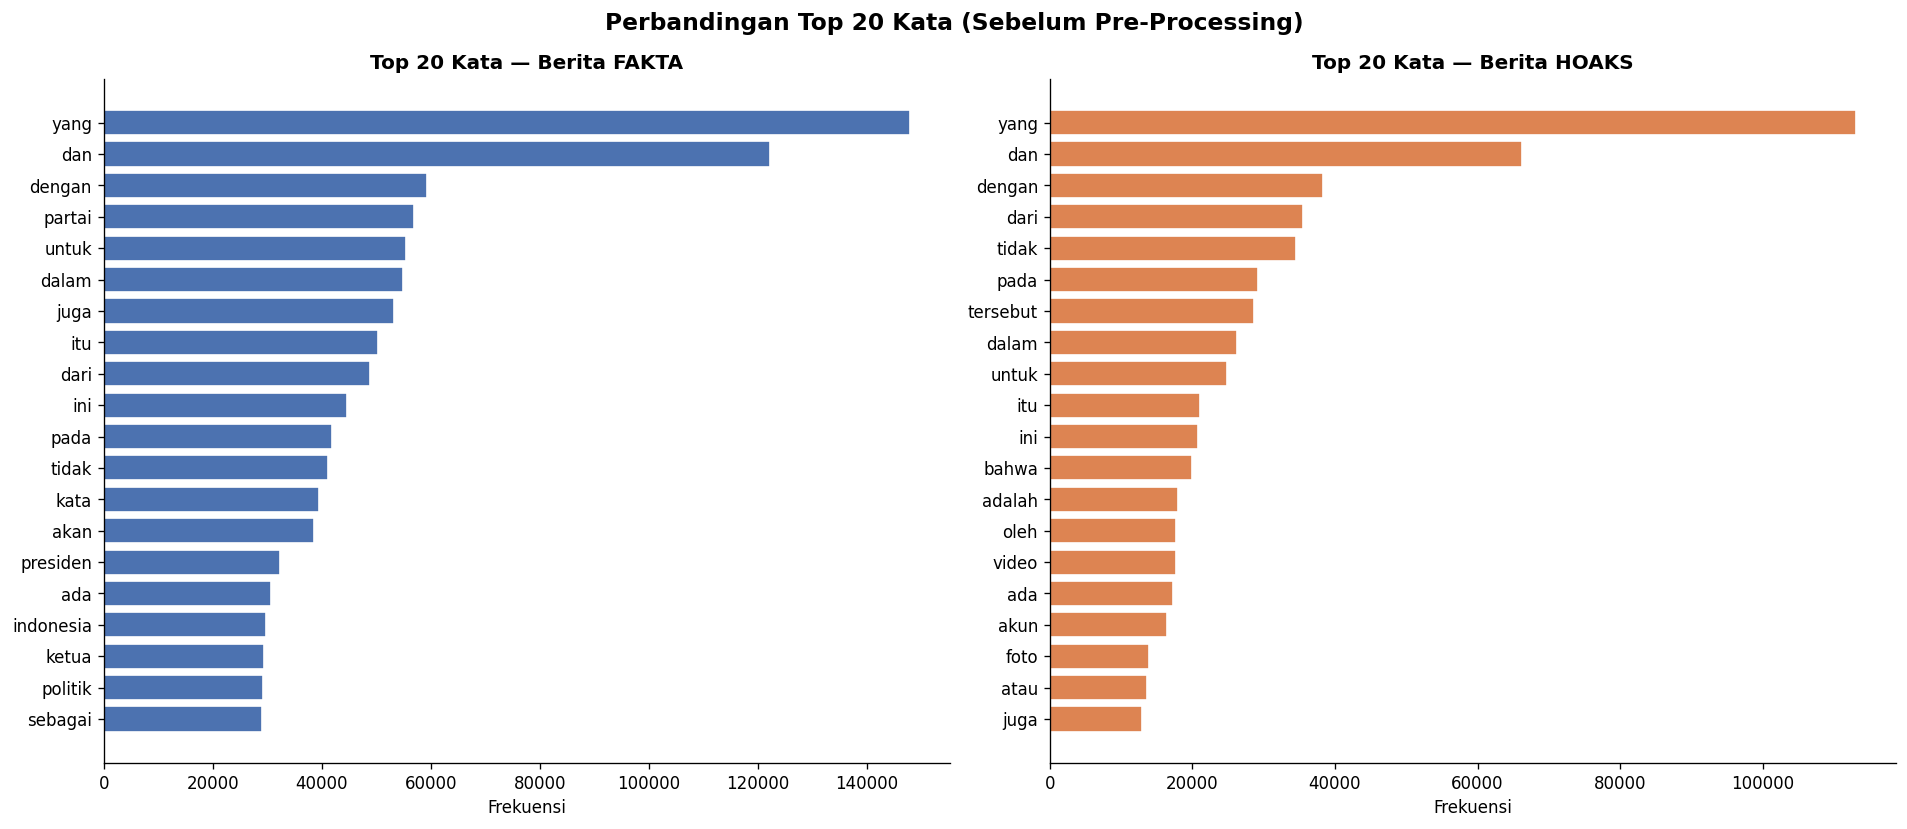

In [ ]:
from collections import Counter

def get_top_words(teks, n=20):
    """Ambil n kata paling sering muncul dari string teks"""
    kata = teks.lower().split()
    # Filter kata yang terlalu pendek
    kata = [k for k in kata if len(k) > 2]
    return Counter(kata).most_common(n)

top_fakta = get_top_words(teks_fakta)
top_hoaks = get_top_words(teks_hoaks)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top kata fakta
kata_f, freq_f = zip(*top_fakta)
axes[0].barh(list(reversed(kata_f)), list(reversed(freq_f)),
             color='#4C72B0', edgecolor='white')
axes[0].set_title('Top 20 Kata — Berita FAKTA', fontweight='bold')
axes[0].set_xlabel('Frekuensi')

# Top kata hoaks
kata_h, freq_h = zip(*top_hoaks)
axes[1].barh(list(reversed(kata_h)), list(reversed(freq_h)),
             color='#DD8452', edgecolor='white')
axes[1].set_title('Top 20 Kata — Berita HOAKS', fontweight='bold')
axes[1].set_xlabel('Frekuensi')

plt.suptitle('Perbandingan Top 20 Kata (Sebelum Pre-Processing)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('top_kata_raw.png', dpi=150, bbox_inches='tight')
plt.show()

# **5. PRE PROCESSING**

In [ ]:
# =============================================================================
# 4. PRE-PROCESSING
# =============================================================================
print("\n" + "=" * 65)
print("  TAHAP 4: PRE-PROCESSING")
print("=" * 65)

# ── Inisialisasi alat NLP ─────────────────────────────────────────
print("\n  [INFO] Menginisialisasi stemmer & stopword remover (Sastrawi)...")

# Stopword Indonesia (Sastrawi + tambahan)
sw_factory        = StopWordRemoverFactory()
sastrawi_stopwords = set(sw_factory.get_stop_words())
additional_stops  = {
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'dengan',
    'untuk', 'pada', 'adalah', 'dalam', 'juga', 'sudah', 'sudah',
    'akan', 'ada', 'tidak', 'bisa', 'kata', 'oleh', 'lebih',
    'saat', 'bagi', 'hal', 'karena', 'serta', 'agar', 'atau',
    'namun', 'tetapi', 'jika', 'maka', 'seperti', 'antara',
    'belum', 'dapat', 'harus', 'masih', 'meski', 'bahwa',
    'http', 'https', 'www', 'com', 'id', 'net',
}
STOP_WORDS = sastrawi_stopwords | additional_stops

# Stemmer Sastrawi
stem_factory = StemmerFactory()
stemmer      = stem_factory.create_stemmer()

# Normalisasi kata tidak baku → baku (contoh sederhana)
kamus_alay = pd.read_csv(
    'new_kamusalay.csv',
    encoding='latin-1',
    header=None
)

kamus_alay.columns = [
    'slang',
    'formal'
]

kamus_normalisasi = dict(
    zip(
        kamus_alay['slang'],
        kamus_alay['formal']
    )
)

def normalize(tokens):
    return [
        kamus_normalisasi[word]
        if word in kamus_normalisasi
        else word
        for word in tokens
    ]

def preprocess_text(text: str) -> str:
    """
    Pipeline pre-processing lengkap:
    1. Lowercase
    2. Cleaning (hapus URL, angka, karakter non-alfabet)
    3. Tokenisasi
    4. Normalisasi slang (menggunakan kamus_normalisasi)
    5. Stopword Removal
    6. Stemming (Sastrawi)
    """
    if not isinstance(text, str): # Handle potential non-string values like NaN
        return ""

    # 1. Lowercase
    text = text.lower()

    # 2. Cleaning
    text = re.sub(r'http\S+|www\.\S+', ' ', text)          # hapus URL
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)               # hapus non-huruf
    text = re.sub(r'\b\w{1,2}\b', ' ', text)               # hapus kata < 3 karakter
    text = re.sub(r'\s+', ' ', text).strip()                # normalisasi spasi

    # 3. Tokenisasi
    tokens = text.split()

    # 4. Normalisasi slang (using the globally defined 'normalize' function)
    tokens = normalize(tokens)

    # 5. Stopword Removal
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 2]

    # 6. Stemming
    tokens = [stemmer.stem(t) for t in tokens]

    return ' '.join(tokens)

# ── Terapkan Pre-Processing ───────────────────────────────────────
print("\n  [INFO] Menerapkan pre-processing pada seluruh dataset...")
print("         (Proses ini membutuhkan waktu beberapa menit karena stemming)\n")

total = len(df)
processed_texts = []
for i, text in enumerate(df[kolom_teks], 1):
    processed_texts.append(preprocess_text(text))
    if i % 200 == 0 or i == total:
        pct = i / total * 100
        bar = '█' * int(pct // 5) + '░' * (20 - int(pct // 5))
        print(f"\r  [{bar}] {pct:5.1f}%  ({i:,}/{total:,})", end='', flush=True)

df['fulltext_clean'] = processed_texts

# Statistik sesudah pre-processing
df['text_length_clean'] = df['fulltext_clean'].str.len()
df['word_count_clean']  = df['fulltext_clean'].str.split().str.len()

print(f"\n\n  ✓  Pre-processing selesai!")
print(f"\n  Contoh perbandingan (artikel pertama):")
print(f"  SEBELUM: {df[kolom_teks].iloc[0][:150]}...")
print(f"  SESUDAH: {df['fulltext_clean'].iloc[0][:150]}...")

# Hapus baris yang menjadi kosong setelah preprocessing
df = df[df['fulltext_clean'].str.strip().str.len() > 10].copy()
df.reset_index(drop=True, inplace=True)
print(f"\n  Dataset final setelah preprocessing: {len(df):,} artikel")

# Add 'label_name' column to df for the final print statement
df['label_name'] = df['label'].map({0: 'Fakta', 1: 'Hoaks'})

print("\n  Statistik Jumlah Kata Setelah Pre-Processing:")
print(df.groupby('label_name')['word_count_clean'].describe().round(1).to_string())


  TAHAP 4: PRE-PROCESSING

  [INFO] Menginisialisasi stemmer & stopword remover (Sastrawi)...

  [INFO] Menerapkan pre-processing pada seluruh dataset...
         (Proses ini membutuhkan waktu beberapa menit karena stemming)

  [████████████████████] 100.0%  (31,726/31,726)

  ✓  Pre-processing selesai!

  Contoh perbandingan (artikel pertama):
  SEBELUM: Jakarta, CNN Indonesia -- Mantan Gubernur DKI Jakarta Anies Baswedan menghadiri acara tasyakuran Milad ke-42 tahun Badan Kontak Majelis Taklim (BKMT) ...
  SESUDAH: jakarta cnn indonesia mantan gubernur daerah khusus ibukota jakarta anies baswedan hadir acara tasyakur milad tahun badan kontak majelis taklim bkmt i...

  Dataset final setelah preprocessing: 31,310 artikel

  Statistik Jumlah Kata Setelah Pre-Processing:
              count   mean    std   min    25%    50%    75%     max
label_name                                                          
Fakta       20945.0  272.9  111.1  39.0  205.0  255.0  317.0  2249.0
Hoaks      

In [ ]:
# Handling missing & duplikat SETELAH preprocessing selesai
print(f"Sebelum : {len(df):,} baris")
print(f"Missing : {df['fulltext_clean'].isnull().sum():,}")
print(f"Duplikat: {df.duplicated(subset=['fulltext_clean']).sum():,}")

df.dropna(subset=['fulltext_clean'], inplace=True)
df.drop_duplicates(subset=['fulltext_clean'], inplace=True)
df = df[df['fulltext_clean'].str.strip().str.len() > 10].copy()
df.reset_index(drop=True, inplace=True)

df.to_csv('df_preprocessed.csv', index=False)

print(f"Sesudah : {len(df):,} baris")
print("Tersimpan!")

Sebelum : 31,310 baris
Missing : 0
Duplikat: 17
Sesudah : 31,293 baris
Tersimpan!


# **6. IMPORT LIBRARY DAN LOAD DATASET BERSIH**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd
import re

In [ ]:
# Load dataset hasil preprocessing
df = pd.read_csv('df_preprocessed.csv')

# Pastikan kolom label bertipe int
df['label']      = df['label'].astype(int)
df['label_name'] = df['label'].map({0: 'Fakta', 1: 'Hoaks'})
kolom_teks       = 'fulltext_clean'

print(f"\n  ✓  Dataset bersih berhasil di-load!")
print(f"\n  Jumlah data  : {len(df):,} artikel")
print(f"  Jumlah kolom : {df.shape[1]}")
print(f"\n  Distribusi kelas:")
for label, jumlah in df['label_name'].value_counts().items():
    print(f"  {label:6s} : {jumlah:,} ({jumlah/len(df)*100:.1f}%)")

print(f"\n  Contoh data bersih:")
df.head()


  ✓  Dataset bersih berhasil di-load!

  Jumlah data  : 31,293 artikel
  Jumlah kolom : 8

  Distribusi kelas:
  Fakta  : 20,943 (66.9%)
  Hoaks  : 10,350 (33.1%)

  Contoh data bersih:


,FullText,label,sumber,jumlah_kata,fulltext_clean,text_length_clean,word_count_clean,label_name
0,"Jakarta, CNN Indonesia -- Mantan Gubernur DKI ...",0,CNN Indonesia,292,jakarta cnn indonesia mantan gubernur daerah k...,1554,237,Fakta
1,"Medan, CNN Indonesia -- Gubernur Sumatera Utar...",0,CNN Indonesia,321,medan cnn indonesia gubernur sumatra utara edy...,1328,213,Fakta
2,"Jakarta, CNN Indonesia -- Partai Kebangkitan B...",0,CNN Indonesia,210,jakarta cnn indonesia partai bangkit bangsa pa...,1363,196,Fakta
3,"Jakarta, CNN Indonesia -- Ketua Umum Partai Ke...",0,CNN Indonesia,213,jakarta cnn indonesia ketua umum partai bangki...,1139,173,Fakta
4,"Jakarta, CNN Indonesia -- Dewan Pimpinan Pusat...",0,CNN Indonesia,226,jakarta cnn indonesia dewan pimpin pusat dasar...,1194,182,Fakta


In [ ]:
# Hapus kolom yang tidak diperlukan
df.drop(columns=['FullText', 'jumlah_kata', 'text_length_clean'], inplace=True)

print("Kolom setelah cleaning:")
print(df.columns.tolist())
df.head(3)

Kolom setelah cleaning:
['label', 'sumber', 'fulltext_clean', 'word_count_clean', 'label_name']


,label,sumber,fulltext_clean,word_count_clean,label_name
0,0,CNN Indonesia,jakarta cnn indonesia mantan gubernur daerah k...,237,Fakta
1,0,CNN Indonesia,medan cnn indonesia gubernur sumatra utara edy...,213,Fakta
2,0,CNN Indonesia,jakarta cnn indonesia partai bangkit bangsa pa...,196,Fakta


## SOURCE LEAKAGE WORDS

In [ ]:
print("\n" + "=" * 60)
print("SOURCE LEAKAGE CLEANING")
print("=" * 60)

# Kata-kata yang berpotensi menyebabkan source bias
source_leakage_words = [
    # ======= NAMA MEDIA (sudah ada) =======
    'cnn indonesia', 'cnn', 'kompas', 'kompas com',
    'tempo', 'tempo co', 'turnbackhoax', 'turn back hoax',
    'facebook', 'instagram', 'twitter', 'youtube',

    # ======= TAMBAHAN NAMA MEDIA =======
    'detik', 'detik com', 'tribun', 'tribunnews',
    'liputan6', 'antara', 'republika', 'okezone',
    'merdeka', 'sindonews', 'jpnn', 'suara com',
    'kumparan', 'medcom', 'tiktok', 'whatsapp',
    'telegram', 'kominfo',

    # ======= TEMPLATE FACT-CHECKER =======
    # (ini yang jadi penyebab utama akurasi 100%!)
    'narasi', 'referensi', 'kategori konten', 'konten sesat',
    'periksa fakta', 'hasil periksa', 'telusur', 'cek fakta',
    'fakta', 'hoaks', 'hoax', 'sesat', 'menyesatkan',
    'disinformasi', 'misinformasi',

    # ======= TEMPLATE PENYEBARAN =======
    'beredar', 'viral', 'unggah', 'diunggah',
    'klaim', 'mengklaim', 'diklaim',
    'screenshot', 'tangkapan layar',
    'akun', 'postingan', 'kiriman',
    'artikel', 'judul', 'konten',
]

# Hapus source leakage words
for word in source_leakage_words:

    df['fulltext_clean'] = df['fulltext_clean'].apply(
        lambda text: re.sub(
            rf'\b{re.escape(word)}\b',
            ' ',
            str(text)
        )
    )

# Rapikan spasi berlebih
df['fulltext_clean'] = (
    df['fulltext_clean']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

print("✓ Source leakage words berhasil dibersihkan!")

print("\nContoh hasil cleaning:")
df[['sumber', 'fulltext_clean']].head()


SOURCE LEAKAGE CLEANING
✓ Source leakage words berhasil dibersihkan!

Contoh hasil cleaning:


,sumber,fulltext_clean
0,CNN Indonesia,jakarta mantan gubernur daerah khusus ibukota ...
1,CNN Indonesia,medan gubernur sumatra utara edy rahmayadi buk...
2,CNN Indonesia,jakarta partai bangkit bangsa partai bangkit b...
3,CNN Indonesia,jakarta ketua umum partai bangkit nusantara pk...
4,CNN Indonesia,jakarta dewan pimpin pusat dasar kena pajak pa...


# **7. EDA LANJUTAN**

## 7.1 Distribusi Kelas Setelah Pre-Processing

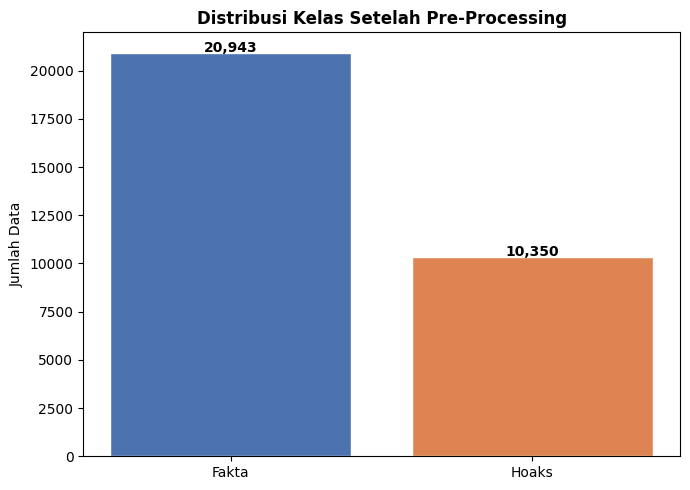

  Fakta : 20,943 (66.9%)
  Hoaks : 10,350 (33.1%)


In [ ]:
dist_kelas = df['label'].value_counts()

plt.figure(figsize=(7, 5))
colors = ['#4C72B0', '#DD8452']
bars   = plt.bar(['Fakta', 'Hoaks'], dist_kelas.values, color=colors, edgecolor='white')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50,
             f'{int(yval):,}', ha='center', fontweight='bold')

plt.title('Distribusi Kelas Setelah Pre-Processing', fontweight='bold')
plt.ylabel('Jumlah Data')
plt.tight_layout()
plt.savefig('distribusi_kelas_clean.png', dpi=150)
plt.show()

for label, name in [(0, 'Fakta'), (1, 'Hoaks')]:
    n = dist_kelas[label]
    print(f"  {name:6s}: {n:,} ({n/len(df)*100:.1f}%)")

## 7.2 Distribusi Panjang Teks Setelah Pre-Processing


             mean  min   max
label_name                  
Fakta       272.9   39  2249
Hoaks       283.3    4  3802


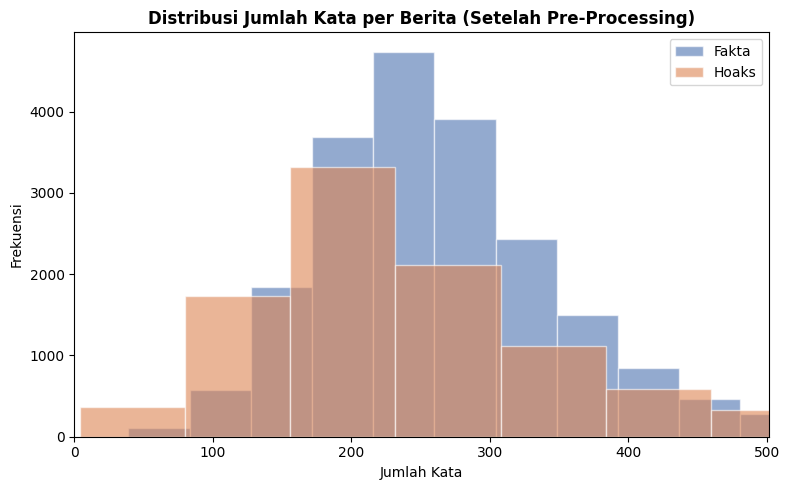

In [ ]:
stats = df.groupby('label_name')['word_count_clean'].agg(['mean', 'min', 'max']).round(1)
print(f"\n{stats.to_string()}")

plt.figure(figsize=(8, 5))
for label, color, name in [(0, '#4C72B0', 'Fakta'), (1, '#DD8452', 'Hoaks')]:
    subset = df[df['label'] == label]['word_count_clean']
    plt.hist(subset, bins=50, alpha=0.6, color=color, label=name, edgecolor='white')

plt.title('Distribusi Jumlah Kata per Berita (Setelah Pre-Processing)', fontweight='bold')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.legend()
plt.xlim(0, df['word_count_clean'].quantile(0.95))
plt.tight_layout()
plt.savefig('panjang_teks_clean.png', dpi=150)
plt.show()

## 7.3 Word Cloud Setelah Pre-Processing

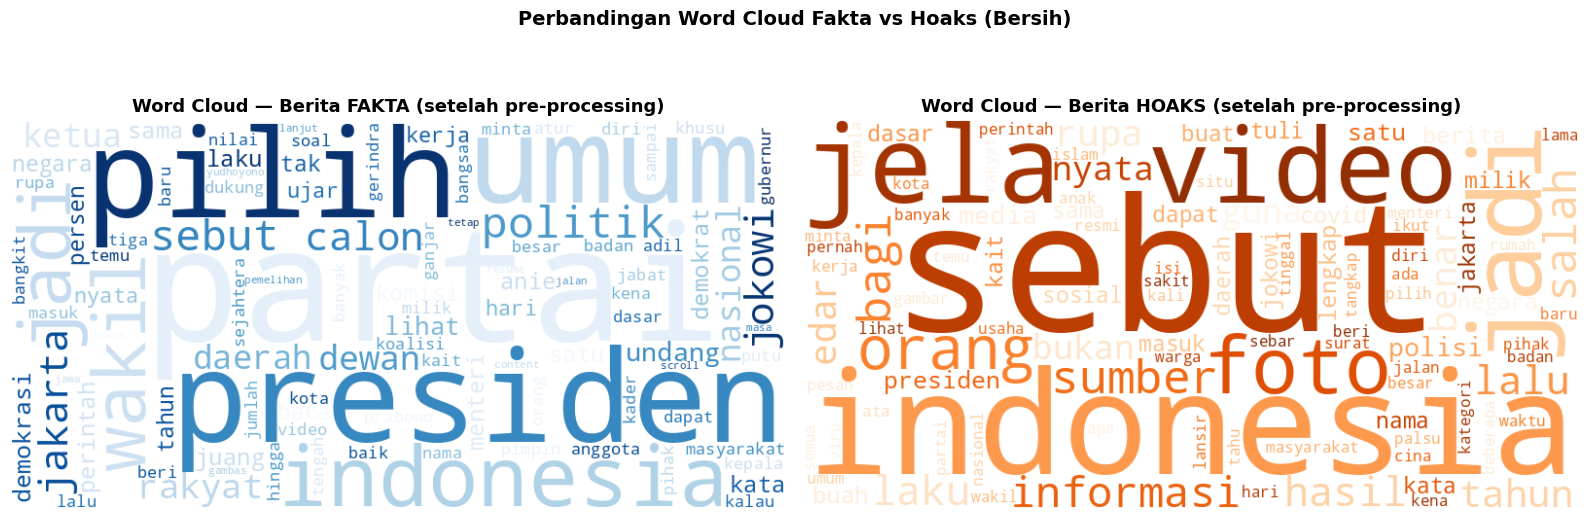

In [ ]:
from wordcloud import WordCloud

teks_fakta = ' '.join(df[df['label'] == 0]['fulltext_clean'].astype(str).tolist())
teks_hoaks = ' '.join(df[df['label'] == 1]['fulltext_clean'].astype(str).tolist())

wc_fakta = WordCloud(width=800, height=400, background_color='white',
                     colormap='Blues',   max_words=100,
                     collocations=False).generate(teks_fakta)
wc_hoaks = WordCloud(width=800, height=400, background_color='white',
                     colormap='Oranges', max_words=100,
                     collocations=False).generate(teks_hoaks)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(wc_fakta, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Word Cloud — Berita FAKTA (setelah pre-processing)',
                  fontweight='bold', fontsize=13)
axes[1].imshow(wc_hoaks, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Word Cloud — Berita HOAKS (setelah pre-processing)',
                  fontweight='bold', fontsize=13)

plt.suptitle('Perbandingan Word Cloud Fakta vs Hoaks (Bersih)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('wordcloud_clean.png', dpi=150, bbox_inches='tight')
plt.show()

## 7.4 Top 20 Kata Setelah Pre-Processing

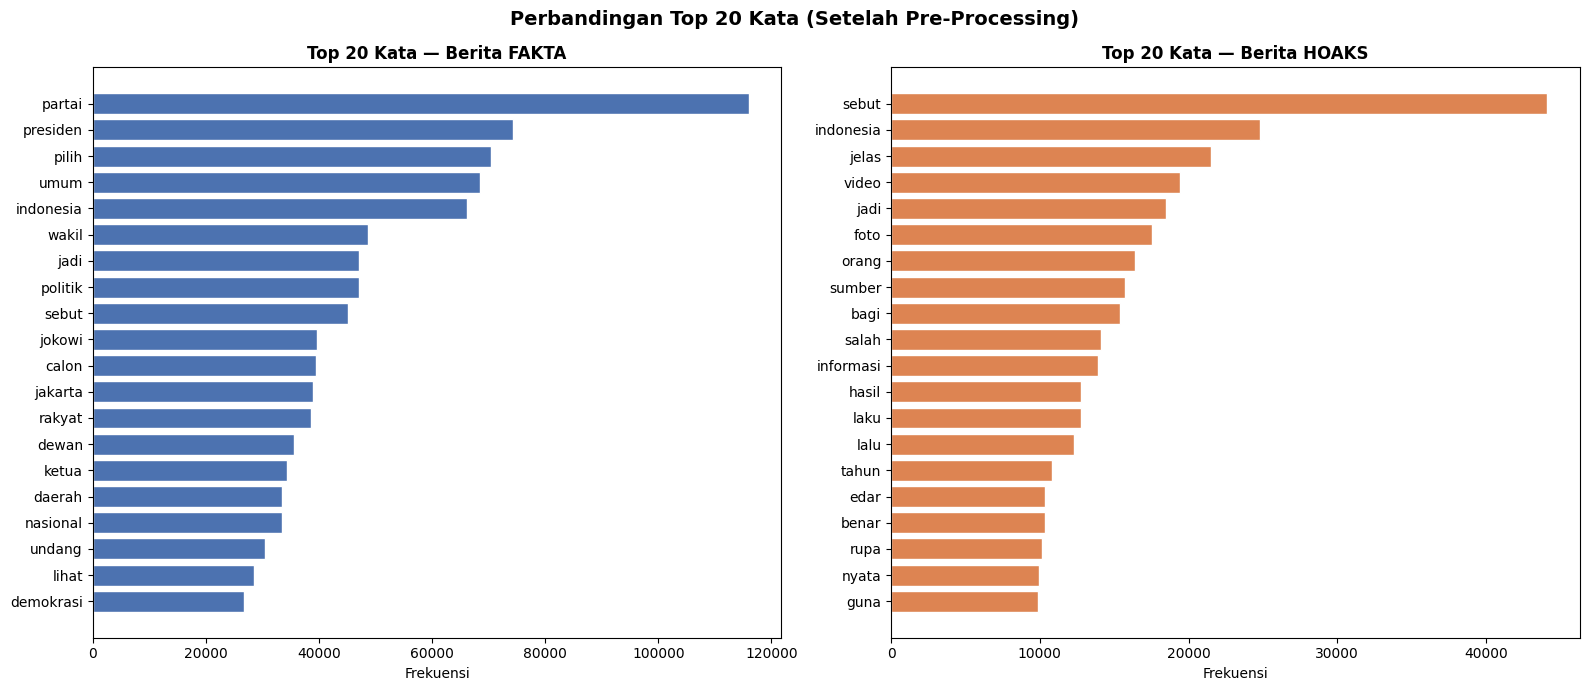

In [ ]:
from collections import Counter

def get_top_words(teks, n=20):
    kata = [k for k in teks.split() if len(k) > 2]
    return Counter(kata).most_common(n)

top_fakta = get_top_words(teks_fakta)
top_hoaks = get_top_words(teks_hoaks)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

kata_f, freq_f = zip(*top_fakta)
axes[0].barh(list(reversed(kata_f)), list(reversed(freq_f)),
             color='#4C72B0', edgecolor='white')
axes[0].set_title('Top 20 Kata — Berita FAKTA', fontweight='bold')
axes[0].set_xlabel('Frekuensi')

kata_h, freq_h = zip(*top_hoaks)
axes[1].barh(list(reversed(kata_h)), list(reversed(freq_h)),
             color='#DD8452', edgecolor='white')
axes[1].set_title('Top 20 Kata — Berita HOAKS', fontweight='bold')
axes[1].set_xlabel('Frekuensi')

plt.suptitle('Perbandingan Top 20 Kata (Setelah Pre-Processing)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('top_kata_clean.png', dpi=150, bbox_inches='tight')
plt.show()

# **8. SPLIT DATA**

Dilakukan proses split data test dan train dahulu agar tidak terjadi kebocoran data. Proses TF IDF ini harus dibagi dulu menjadi data train dan test, nah data train nanti akan dilakukan tf idf untuk membangun kamus dan hitung bobotnya. Selanjutnya untuk data test nanti akan jadi simulasi data baru untuk menilai performa model.

In [ ]:
X = df['fulltext_clean']
y = df['label']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Menjaga proporsi kelas tetap seimbang
)

print("\n" + "=" * 50)
print("TRAIN TEST SPLIT (80:20)")
print("=" * 50)
print(f"Total data train : {len(X_train_raw)} ({len(X_train_raw)/len(X)*100:.1f}%) Kishan)")
print(f"Total data test  : {len(X_test_raw)} ({len(X_test_raw)/len(X)*100:.1f}%) Kishan)")
print(f"\nDistribusi label data train:")
print(y_train.value_counts())
print(f"\nDistribusi label data test:")
print(y_test.value_counts())


TRAIN TEST SPLIT (80:20)
Total data train : 25034 (80.0%) Kishan)
Total data test  : 6259 (20.0%) Kishan)

Distribusi label data train:
label
0    16754
1     8280
Name: count, dtype: int64

Distribusi label data test:
label
0    4189
1    2070
Name: count, dtype: int64


# **9. TF IDF**

Pada proses ini, semua kata akan dilakukan TF IDF, hanya saja mengambil 5000 untuk kata yang memiliki bobot tertinggi/kata penting saja dan sisa kata lain tetap ada(diabaikan). Alasan diambil hanya 5000 karena akan lebih ringan dan seimbang untuk proses matriks nya nanti dan biasanya memang diambil sekitar 5000. Hasil TF IDF ini memiliki data train dan test, untuk data train terdapat 25.034 baris dan 5000 kolom. Begitu juga dengan data test yang memiliki baris sekitar 6259 dan 5000 kolom.
- Setiap baris = 1 berita
- Setiap kolom = 1 kata
- Setiap angka = bobot TF-IDF kata tersebut di berita tersebut
- Angka 0.000 = kata itu tidak muncul di berita tersebut

In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,      # Ambil 5000 fitur/kata terpenting
    ngram_range=(1, 2),     # Unigram dan bigram
    min_df=2,               # Kata harus muncul minimal di 2 dokumen
    max_df=0.95,            # Abaikan kata yang muncul di >95% dokumen
    sublinear_tf=True       # Gunakan log normalization pada TF
)

# Fit hanya pada data train, transform ke train & test
X_train = tfidf.fit_transform(X_train_raw)
X_test  = tfidf.transform(X_test_raw)

print("\n" + "=" * 50)
print("TF-IDF FEATURE EXTRACTION")
print("=" * 50)
print(f"Parameter TF-IDF:")
print(f"  - max_features : 5000")
print(f"  - ngram_range  : (1, 2) — unigram & bigram")
print(f"  - min_df       : 2")
print(f"  - max_df       : 0.95")
print(f"  - sublinear_tf : True")
print(f"\nHasil TF-IDF:")
print(f"  - Shape X_train : {X_train.shape} (dokumen x fitur)")
print(f"  - Shape X_test  : {X_test.shape} (dokumen x fitur)")
print(f"  - Tipe matriks  : Sparse Matrix")



TF-IDF FEATURE EXTRACTION
Parameter TF-IDF:
  - max_features : 5000
  - ngram_range  : (1, 2) — unigram & bigram
  - min_df       : 2
  - max_df       : 0.95
  - sublinear_tf : True

Hasil TF-IDF:
  - Shape X_train : (25034, 5000) (dokumen x fitur)
  - Shape X_test  : (6259, 5000) (dokumen x fitur)
  - Tipe matriks  : Sparse Matrix


Menampilkan 10 kata dengan bobot yang paling tertinggi. Untuk kata-kata dengan bobot tertinggi adalag Partai dan Indonesia.

In [ ]:
# Ambil nama fitur dan rata-rata bobot TF-IDF per kata
feature_names = tfidf.get_feature_names_out()
mean_tfidf = np.asarray(X_train.mean(axis=0)).flatten()

# Buat dataframe bobot
df_bobot = pd.DataFrame({
    'kata': feature_names,
    'bobot_tfidf': mean_tfidf
}).sort_values('bobot_tfidf', ascending=False).reset_index(drop=True)

# Tampilkan top 10
print("TOP 10 KATA DENGAN BOBOT TF-IDF TERTINGGI:")
print(df_bobot.head(10).to_string(index=False))

TOP 10 KATA DENGAN BOBOT TF-IDF TERTINGGI:
     kata  bobot_tfidf
   partai     0.030747
    sebut     0.029416
 presiden     0.027898
indonesia     0.027731
    pilih     0.026227
     jadi     0.024971
     umum     0.024935
  politik     0.022852
    wakil     0.022182
  jakarta     0.020975


# **10. Feature Selection (Chi-Square)**

Setelah data training seimbang, selanjutnya dilakukan proses seleksi fitur untuk mereduksi fitur-fitur yang tidak relevan untuk digunakan dalam proses klasifikasi. Seleksi fitur yang digunakan dalam project adalah Chi-Square.

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2

Import Library untuk insialisasi feature selection dan memilih korelasi paling kuat terhadap label sehingga dapat meningkatkan akurasi klasifikasi.

In [ ]:
k_best = 2000

Menentukan 3000 fitur terbaik untuk selanjutnya dipilih melalui SelectKBest.

In [ ]:
chi2_selector = SelectKBest(score_func=chi2,k=k_best)

Menggunakan k_best sebagai parameter jumlah fitur terbaik dan membuat chi-square selector dengan metode (`SelectKBest`) dan score_func (`chi2`)

In [ ]:
X_train_dense = X_train.toarray()
X_test_dense  = X_test.toarray()

Membangun inisialisasi fitur seleksi dari data training yang sudah seimbang dan mempertahankan fitur-fitur terbaik yang dipertahankan.

In [ ]:
X_train_chi2_raw = chi2_selector.fit_transform(X_train_dense, y_train)
X_test_chi2      = chi2_selector.transform(X_test_dense)

print(f"Jumlah fitur sebelum seleksi : {X_train.shape[1]}")
print(f"Jumlah fitur sesudah seleksi : {X_train_chi2_raw.shape[1]}")

print("\nShape data setelah feature selection:")
print(f"X_train_chi2_raw : {X_train_chi2_raw.shape}")
print(f"X_test_chi2      : {X_test_chi2.shape}")

# Ambil nama & score fitur terpilih
feature_names     = np.array(tfidf.get_feature_names_out())
selected_features = feature_names[chi2_selector.get_support()]
selected_scores   = chi2_selector.scores_[chi2_selector.get_support()]

Jumlah fitur sebelum seleksi : 5000
Jumlah fitur sesudah seleksi : 2000

Shape data setelah feature selection:
X_train_chi2_raw : (25034, 2000)
X_test_chi2      : (6259, 2000)


Mengambil nama fitur dari hasil ekstraksi TF-IDF, dan mengambil fitur dan score chi-square terpilih.

In [ ]:
df_train = X_train_raw.reset_index(drop=True).to_frame()
df_train['label'] = y_train.reset_index(drop=True)

fakta_total = (df_train['label'] == 0).sum()
hoaks_total = (df_train['label'] == 1).sum()

# Dataframe fitur chi-square
top20 = (
    pd.DataFrame({
        'fitur': selected_features,
        'score_chi2': selected_scores
    })
    .sort_values('score_chi2', ascending=False)
    .head(20)
    .reset_index(drop=True)
)

# Hitung distribusi fitur dari data TRAIN saja
hasil = []

for fitur in top20['fitur']:

    n_fakta = df_train[df_train['label'] == 0]['fulltext_clean'] \
        .str.contains(fitur, na=False).sum()

    n_hoaks = df_train[df_train['label'] == 1]['fulltext_clean'] \
        .str.contains(fitur, na=False).sum()

    pct_fakta = round(n_fakta / fakta_total * 100, 1)
    pct_hoaks = round(n_hoaks / hoaks_total * 100, 1)

    dominan = 'Hoaks' if pct_hoaks > pct_fakta else 'Fakta'

    hasil.append([
        fitur,
        round(top20.loc[top20['fitur'] == fitur,
                        'score_chi2'].values[0], 2),
        n_fakta,
        pct_fakta,
        n_hoaks,
        pct_hoaks,
        dominan
    ])

# Dataframe final
df_top20 = pd.DataFrame(hasil, columns=[
    'Fitur',
    'Score χ²',
    'N Fakta',
    '% Fakta',
    'N Hoaks',
    '% Hoaks',
    'Dominan'
])

print("\nTOP 20 FITUR CHI-SQUARE DENGAN DISTRIBUSI KELAS\n")
print(df_top20.to_string(index=False))


TOP 20 FITUR CHI-SQUARE DENGAN DISTRIBUSI KELAS

        Fitur  Score χ²  N Fakta  % Fakta  N Hoaks  % Hoaks Dominan
       sumber    563.26     1027      6.1     7785     94.0   Hoaks
         foto    506.09      795      4.7     3250     39.3   Hoaks
         edar    425.56      782      4.7     4260     51.4   Hoaks
     kategori    353.35      251      1.5     3380     40.8   Hoaks
        palsu    330.88       95      0.6     1770     21.4   Hoaks
        jelas    312.46     5005     29.9     7773     93.9   Hoaks
 lengkap bagi    304.48        0      0.0     2811     33.9   Hoaks
   bagi jelas    287.78       29      0.2     2848     34.4   Hoaks
    informasi    283.53     2043     12.2     4187     50.6   Hoaks
       partai    282.95    11530     68.8      689      8.3   Fakta
  video sebut    281.99      116      0.7     1375     16.6   Hoaks
      lengkap    273.56     1156      6.9     4621     55.8   Hoaks
         asli    263.60      264      1.6     1806     21.8   Hoak

# **11. Handling Imbalance SMOTE**

In [ ]:
from imblearn.over_sampling import SMOTE

Cek distribusi label sebelum SMOTE

In [ ]:
print("Distribusi kelas sebelum SMOTE:")
print(y_train.value_counts())

Distribusi kelas sebelum SMOTE:
label
0    16754
1     8280
Name: count, dtype: int64


In [ ]:
smote = SMOTE(random_state=42)

Terapkan SMOTE hanya pada data training

In [ ]:
X_train_smote, y_train_smote = smote.fit_resample(X_train_chi2_raw, y_train)

Cek distribusi label setelah SMOTE

In [ ]:
print("\nDistribusi kelas setelah SMOTE:")
print(y_train_smote.value_counts())


Distribusi kelas setelah SMOTE:
label
1    16754
0    16754
Name: count, dtype: int64


Cek ukuran data

In [ ]:
print("\nUkuran data setelah SMOTE:")
print("X_train_smote:", X_train_smote.shape)
print("y_train_smote:", y_train_smote.shape)


Ukuran data setelah SMOTE:
X_train_smote: (33508, 2000)
y_train_smote: (33508,)


Hasil penerapan Synthetic Minority Oversampling Technique (SMOTE) berhasil menyeimbangkan jumlah data pada kedua kelas menjadi masing-masing 16.754 data sehingga distribusi data training menjadi lebih seimbang untuk proses klasifikasi.

# **12. MODELLING**

## **12.1 Naive Bayes**

### **1. Multinomial Naive Bayes**

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import time

hasil feature selection

In [ ]:
X_train_chi2 = X_train_chi2_raw

Inisialisasi Model

In [ ]:
nb_model = MultinomialNB()

print("\n[INFO] Training Multinomial Naive Bayes...\n")


[INFO] Training Multinomial Naive Bayes...



Hitung Waktu Komputasi Training

In [ ]:
start_train = time.time()

nb_model.fit(
    X_train_smote,   # data training hasil SMOTE
    y_train_smote
)

end_train = time.time()

training_time = end_train - start_train

print("✓ Training selesai!")

✓ Training selesai!


Hitung Waktu Komputasi Prediksi

In [ ]:
start_test = time.time()

y_pred_nb = nb_model.predict(
    X_test_chi2
)

end_test = time.time()

testing_time = end_test - start_test

Evaluasi Model

In [ ]:
accuracy_nb = accuracy_score(
    y_test,
    y_pred_nb
)

print("\n" + "=" * 60)
print("HASIL EVALUASI MULTINOMIAL NAIVE BAYES")
print("=" * 60)

print(f"\nAccuracy : {accuracy_nb:.4f}")

print(f"\nWaktu Training : {training_time:.4f} detik")
print(f"Waktu Testing  : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI MULTINOMIAL NAIVE BAYES

Accuracy : 0.9730

Waktu Training : 0.1892 detik
Waktu Testing  : 0.0564 detik
Total Waktu Komputasi : 0.2456 detik


Classification Report

In [ ]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=['Fakta', 'Hoaks']
    )
)



Classification Report:

              precision    recall  f1-score   support

       Fakta       0.99      0.97      0.98      4189
       Hoaks       0.94      0.98      0.96      2070

    accuracy                           0.97      6259
   macro avg       0.97      0.97      0.97      6259
weighted avg       0.97      0.97      0.97      6259



Confusion Matrix

<Figure size 600x500 with 0 Axes>

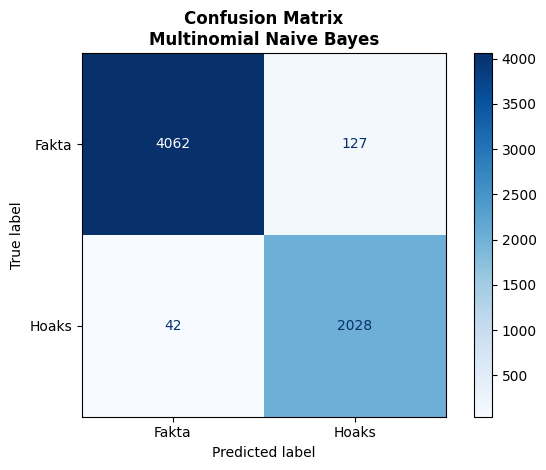

In [ ]:
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb
)

plt.figure(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Fakta', 'Hoaks']
)

disp.plot(
    cmap='Blues',
    values_format='d'
)

plt.title(
    'Confusion Matrix\nMultinomial Naive Bayes',
    fontweight='bold'
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_nb.png',
    dpi=150
)

plt.show()

### **2. Gaussian Naive Bayes**

In [ ]:
from sklearn.naive_bayes import GaussianNB

Inisialisasi Model

In [ ]:
gnb_model = GaussianNB()

print("\n[INFO] Training Gaussian Naive Bayes...\n")


[INFO] Training Gaussian Naive Bayes...



Waktu Komputasi Training

In [ ]:
start_train = time.time()

gnb_model.fit(
    X_train_smote,   # data training hasil SMOTE
    y_train_smote
)

end_train = time.time()

training_time_gnb = end_train - start_train

print("✓ Training selesai!")


✓ Training selesai!


Waktu Komputasi Testing

In [ ]:
start_test = time.time()

y_pred_gnb = gnb_model.predict(
    X_test_chi2
)

end_test = time.time()

testing_time_gnb = end_test - start_test

Evaluasi Model

In [ ]:
accuracy_gnb = accuracy_score(
    y_test,
    y_pred_gnb
)

print("\n" + "=" * 60)
print("HASIL EVALUASI MULTINOMIAL NAIVE BAYES")
print("=" * 60)

print(f"\nAccuracy : {accuracy_gnb:.4f}")

print(f"\nWaktu Training : {training_time_gnb:.4f} detik")
print(f"Waktu Testing  : {testing_time_gnb:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time_gnb + testing_time_gnb):.4f} detik")


HASIL EVALUASI MULTINOMIAL NAIVE BAYES

Accuracy : 0.9685

Waktu Training : 1.2640 detik
Waktu Testing  : 0.1441 detik
Total Waktu Komputasi : 1.4081 detik


Classification Report

In [ ]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_gnb,
        target_names=['Fakta', 'Hoaks']
    )
)


Classification Report:

              precision    recall  f1-score   support

       Fakta       1.00      0.96      0.98      4189
       Hoaks       0.92      0.99      0.95      2070

    accuracy                           0.97      6259
   macro avg       0.96      0.98      0.97      6259
weighted avg       0.97      0.97      0.97      6259



Confusion Matrix

<Figure size 600x500 with 0 Axes>

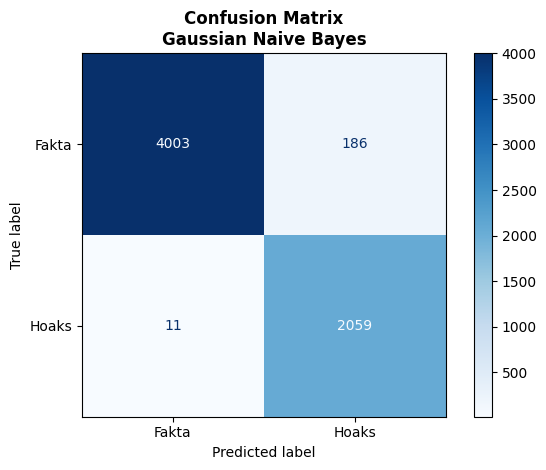

In [ ]:
cm_gnb = confusion_matrix(
    y_test,
    y_pred_gnb
)

plt.figure(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gnb,
    display_labels=['Fakta', 'Hoaks']
)

disp.plot(
    cmap='Blues',
    values_format='d'
)

plt.title(
    'Confusion Matrix\nGaussian Naive Bayes',
    fontweight='bold'
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_gnb.png',
    dpi=150
)

plt.show()

### **3. Bernoulli Naive Bayes**

In [ ]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import time

Binarisasi Data untuk Bernoulli NB

In [ ]:
X_train_bnb = (X_train_smote > 0).astype(int)
X_test_bnb  = (X_test_chi2 > 0).astype(int)


Inisialisasi Model

In [ ]:
bnb_model = BernoulliNB()
print("\nTraining Bernoulli Naive Bayes...\n")


Training Bernoulli Naive Bayes...



Hitung Waktu Komputasi Training

In [ ]:
start_train = time.time()
bnb_model.fit(X_train_bnb, y_train_smote)
end_train = time.time()
training_time = end_train - start_train
print("✓ Training selesai!")

✓ Training selesai!


Hitung Waktu Komputasi Prediksi

In [ ]:
start_test = time.time()
y_pred_bnb = bnb_model.predict(X_test_bnb)
end_test = time.time()
testing_time = end_test - start_test

Evaluasi Model

In [ ]:
accuracy_bnb = accuracy_score(y_test, y_pred_bnb)

print("\n" + "=" * 60)
print("HASIL EVALUASI BERNOULLI NAIVE BAYES")
print("=" * 60)
print(f"\nAccuracy : {accuracy_bnb:.4f}")
print(f"\nWaktu Training        : {training_time:.4f} detik")
print(f"Waktu Testing         : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI BERNOULLI NAIVE BAYES

Accuracy : 0.9609

Waktu Training        : 1.7822 detik
Waktu Testing         : 0.4208 detik
Total Waktu Komputasi : 2.2030 detik


Classification Report

In [ ]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_bnb, target_names=['Fakta', 'Hoaks']))


Classification Report:

              precision    recall  f1-score   support

       Fakta       1.00      0.95      0.97      4189
       Hoaks       0.90      0.99      0.94      2070

    accuracy                           0.96      6259
   macro avg       0.95      0.97      0.96      6259
weighted avg       0.96      0.96      0.96      6259



Confusion Matrix

<Figure size 600x500 with 0 Axes>

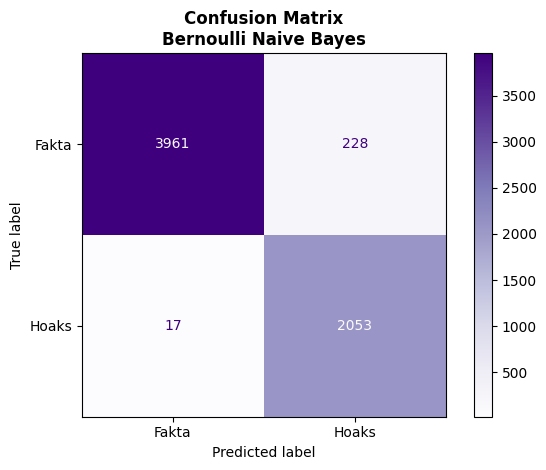

In [ ]:
cm_bnb = confusion_matrix(y_test, y_pred_bnb)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bnb,
    display_labels=['Fakta', 'Hoaks']
)
disp.plot(cmap='Purples', values_format='d')

plt.title('Confusion Matrix\nBernoulli Naive Bayes', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.savefig('confusion_matrix_bnb.png', dpi=150)
plt.show()

### **4. Complement Naive Bayes**

In [ ]:
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
cnb_model = ComplementNB()
print("\nTraining Complement Naive Bayes...\n")


Training Complement Naive Bayes...



In [ ]:
start_train = time.time()
cnb_model.fit(X_train_smote, y_train_smote)
end_train = time.time()
training_time = end_train - start_train
print("✓ Training selesai!")

✓ Training selesai!


In [ ]:
start_test = time.time()
y_pred_cnb = cnb_model.predict(X_test_chi2)
end_test = time.time()
testing_time = end_test - start_test

In [ ]:
accuracy_cnb = accuracy_score(y_test, y_pred_cnb)

print("\n" + "=" * 60)
print("HASIL EVALUASI COMPLEMENT NAIVE BAYES")
print("=" * 60)
print(f"\nAccuracy : {accuracy_cnb:.4f}")
print(f"\nWaktu Training        : {training_time:.4f} detik")
print(f"Waktu Testing         : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI COMPLEMENT NAIVE BAYES

Accuracy : 0.9730

Waktu Training        : 0.5169 detik
Waktu Testing         : 0.0554 detik
Total Waktu Komputasi : 0.5723 detik


In [ ]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_cnb, target_names=['Fakta', 'Hoaks']))


Classification Report:

              precision    recall  f1-score   support

       Fakta       0.99      0.97      0.98      4189
       Hoaks       0.94      0.98      0.96      2070

    accuracy                           0.97      6259
   macro avg       0.97      0.97      0.97      6259
weighted avg       0.97      0.97      0.97      6259



<Figure size 600x500 with 0 Axes>

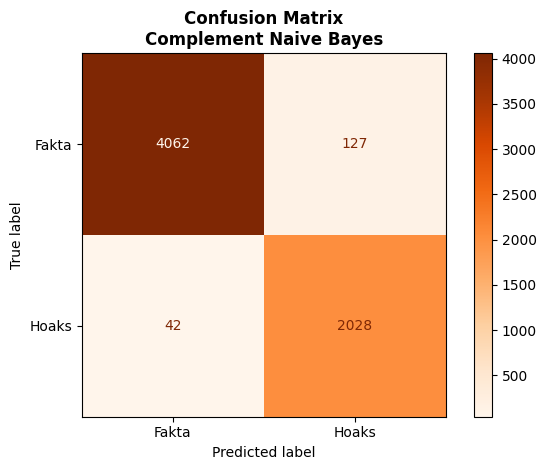

In [ ]:
cm_cnb = confusion_matrix(y_test, y_pred_cnb)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnb,
    display_labels=['Fakta', 'Hoaks']
)
disp.plot(cmap='Oranges', values_format='d')

plt.title('Confusion Matrix\nComplement Naive Bayes', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.savefig('confusion_matrix_cnb.png', dpi=150)
plt.show()

## **12.2 Support Vector Machine (SVM)**

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

### **1. SVM linear**

Inisialisasi Model

In [ ]:
svm_linear = SVC(kernel='linear',C=1, random_state=42)

Hitung Waktu Komputasi Training

In [ ]:
start_train = time.time()

svm_linear.fit(
    X_train_smote,
    y_train_smote)
end_train = time.time()
training_time = end_train - start_train

print("✓ Training selesai!")

✓ Training selesai!


Hitung Waktu Komputasi Test

In [ ]:
start_test = time.time()

y_pred_linear = svm_linear.predict(
    X_test_chi2)
end_test = time.time()
testing_time = end_test - start_test

Akurasi Model SVM Linear

In [ ]:
accuracy_linear = accuracy_score(

    y_test,
    y_pred_linear)

print("\n" + "=" * 60)
print("HASIL EVALUASI SVM LINEAR")
print("=" * 60)
print(f"\nAccuracy : {accuracy_linear:.4f}")
print(f"\nWaktu Training        : {training_time:.4f} detik")
print(f"Waktu Testing         : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI SVM LINEAR

Accuracy : 0.9946

Waktu Training        : 52.0980 detik
Waktu Testing         : 8.8404 detik
Total Waktu Komputasi : 60.9384 detik


Classification Report


In [ ]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=['Fakta', 'Hoaks']))


Classification Report:

              precision    recall  f1-score   support

       Fakta       1.00      0.99      1.00      4189
       Hoaks       0.99      1.00      0.99      2070

    accuracy                           0.99      6259
   macro avg       0.99      0.99      0.99      6259
weighted avg       0.99      0.99      0.99      6259



Confusion Matrix

<Figure size 600x500 with 0 Axes>

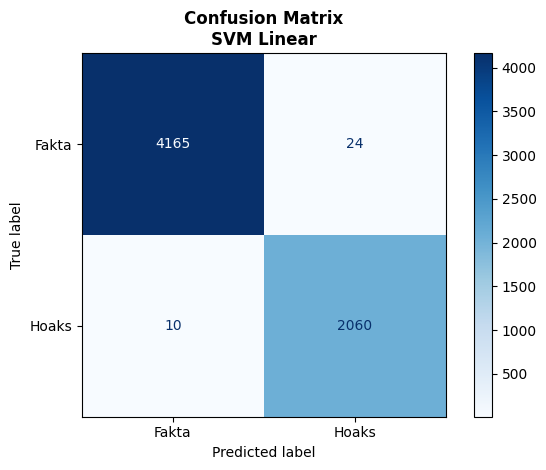

In [ ]:
cm_linear = confusion_matrix(
    y_test,
    y_pred_linear
)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=['Fakta', 'Hoaks']
)

disp.plot(
    cmap='Blues',
    values_format='d'
)

plt.title(
    'Confusion Matrix\nSVM Linear',
    fontweight='bold'
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_svm_linear.png',
    dpi=150
)

plt.show()

### **2. SVM RBF**

Inisialisasi Model

In [ ]:
svm_rbf = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)


Hitung Waktu Komputasi Training

In [ ]:
start_train = time.time()

svm_rbf.fit(
    X_train_smote,
    y_train_smote)
end_train = time.time()
training_time = end_train - start_train

print("✓ Training selesai!")

✓ Training selesai!


Hitung Waktu Komputasi Test


In [ ]:
start_test = time.time()

y_pred_rbf = svm_rbf.predict(
    X_test_chi2)
end_test = time.time()
testing_time = end_test - start_test

Akurasi Model SVM RBF


In [ ]:
accuracy_rbf = accuracy_score(
    y_test,
    y_pred_rbf)

print("\n" + "=" * 60)
print("HASIL EVALUASI SVM RBF")
print("=" * 60)
print(f"\nAccuracy : {accuracy_rbf:.4f}")
print(f"\nWaktu Training        : {training_time:.4f} detik")
print(f"Waktu Testing         : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI SVM RBF

Accuracy : 0.9957

Waktu Training        : 158.0657 detik
Waktu Testing         : 36.9972 detik
Total Waktu Komputasi : 195.0629 detik


Classification Report

In [ ]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rbf,
        target_names=['Fakta', 'Hoaks']))


Classification Report:

              precision    recall  f1-score   support

       Fakta       1.00      1.00      1.00      4189
       Hoaks       0.99      1.00      0.99      2070

    accuracy                           1.00      6259
   macro avg       0.99      1.00      1.00      6259
weighted avg       1.00      1.00      1.00      6259



Confusion Matrix

<Figure size 600x500 with 0 Axes>

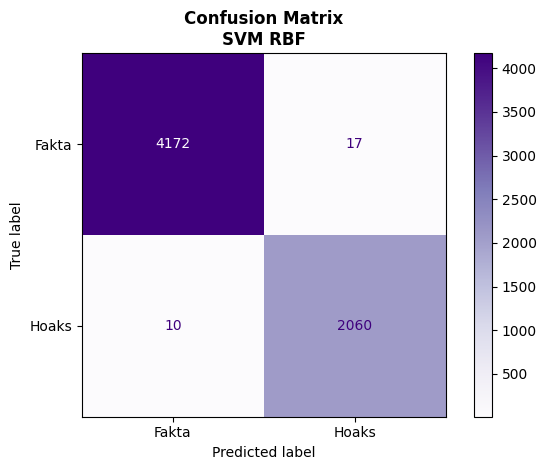

In [ ]:
cm_rbf = confusion_matrix(
    y_test,
    y_pred_rbf)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rbf,
    display_labels=['Fakta', 'Hoaks'])

disp.plot(
    cmap='Purples',
    values_format='d')

plt.title(
    'Confusion Matrix\nSVM RBF',
    fontweight='bold'
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_svm_rbf.png',
    dpi=150
)

plt.show()

### **3. SVM Polynomial**

Inisialisasi Model

In [ ]:
svm_poly = SVC(kernel='poly', degree=3, C=1, gamma='scale', random_state=42)

Hitung Waktu Komputasi Training

In [ ]:
print("\n[INFO] Training SVM Polynomial...\n")

start_train = time.time()

svm_poly.fit(
    X_train_smote,
    y_train_smote
)

end_train = time.time()

training_time = end_train - start_train

print("✓ Training selesai!")


[INFO] Training SVM Polynomial...

✓ Training selesai!


Hitung Waktu Komputasi Test

In [ ]:
start_test = time.time()

y_pred_poly = svm_poly.predict(
    X_test_chi2
)

end_test = time.time()

testing_time = end_test - start_test

Akurasi Model SVM Polynomial

In [ ]:
accuracy_poly = accuracy_score(
    y_test,
    y_pred_poly
)

print("\n" + "=" * 60)
print("HASIL EVALUASI SVM POLYNOMIAL")
print("=" * 60)

print(f"\nAccuracy : {accuracy_poly:.4f}")

print(f"\nWaktu Training        : {training_time:.4f} detik")
print(f"Waktu Testing         : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI SVM POLYNOMIAL

Accuracy : 0.9661

Waktu Training        : 636.3878 detik
Waktu Testing         : 43.2129 detik
Total Waktu Komputasi : 679.6006 detik


Classification Report

In [ ]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_poly,
        target_names=['Fakta', 'Hoaks']
    )
)


Classification Report:

              precision    recall  f1-score   support

       Fakta       1.00      0.95      0.97      4189
       Hoaks       0.91      0.99      0.95      2070

    accuracy                           0.97      6259
   macro avg       0.95      0.97      0.96      6259
weighted avg       0.97      0.97      0.97      6259



Confussion Matrix

<Figure size 600x500 with 0 Axes>

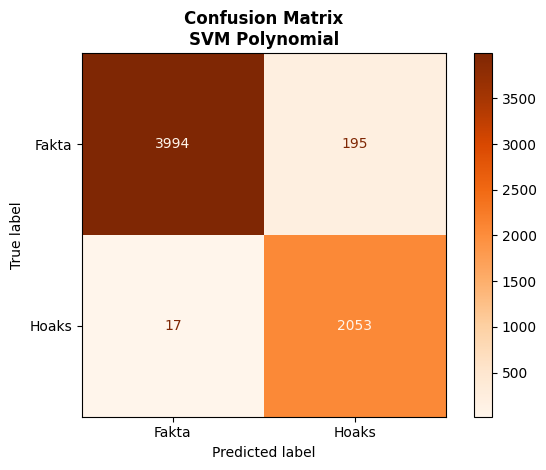

In [ ]:
cm_poly = confusion_matrix(
    y_test,
    y_pred_poly
)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_poly,
    display_labels=['Fakta', 'Hoaks']
)

disp.plot(
    cmap='Oranges',
    values_format='d'
)

plt.title(
    'Confusion Matrix\nSVM Polynomial',
    fontweight='bold'
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_svm_poly.png',
    dpi=150
)

plt.show()

### **4. SVM Sigmoid**

Inisialisasi Model

In [ ]:
svm_sigmoid = SVC(kernel='sigmoid', C=1, gamma='scale', random_state=42)

Hitung Waktu Komputasi Training

In [ ]:
print("\n[INFO] Training SVM Sigmoid...\n")

start_train = time.time()

svm_sigmoid.fit(
    X_train_smote,
    y_train_smote
)

end_train = time.time()

training_time = end_train - start_train

print("✓ Training selesai!")


[INFO] Training SVM Sigmoid...

✓ Training selesai!


Hitung Waktu Komputasi Test

In [ ]:
start_test = time.time()

y_pred_sigmoid = svm_sigmoid.predict(
    X_test_chi2
)

end_test = time.time()

testing_time = end_test - start_test

Akurasi Model SVM Sigmoid

In [ ]:
accuracy_sigmoid = accuracy_score(
    y_test,
    y_pred_sigmoid
)

print("\n" + "=" * 60)
print("HASIL EVALUASI SVM SIGMOID")
print("=" * 60)

print(f"\nAccuracy : {accuracy_sigmoid:.4f}")

print(f"\nWaktu Training        : {training_time:.4f} detik")
print(f"Waktu Testing         : {testing_time:.4f} detik")
print(f"Total Waktu Komputasi : {(training_time + testing_time):.4f} detik")


HASIL EVALUASI SVM SIGMOID

Accuracy : 0.9952

Waktu Training        : 40.4779 detik
Waktu Testing         : 3.3610 detik
Total Waktu Komputasi : 43.8389 detik


Classification Report

In [ ]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_sigmoid,
        target_names=['Fakta', 'Hoaks']
    )
)


Classification Report:

              precision    recall  f1-score   support

       Fakta       1.00      0.99      1.00      4189
       Hoaks       0.99      1.00      0.99      2070

    accuracy                           1.00      6259
   macro avg       0.99      1.00      0.99      6259
weighted avg       1.00      1.00      1.00      6259



Confussion Matrix

<Figure size 600x500 with 0 Axes>

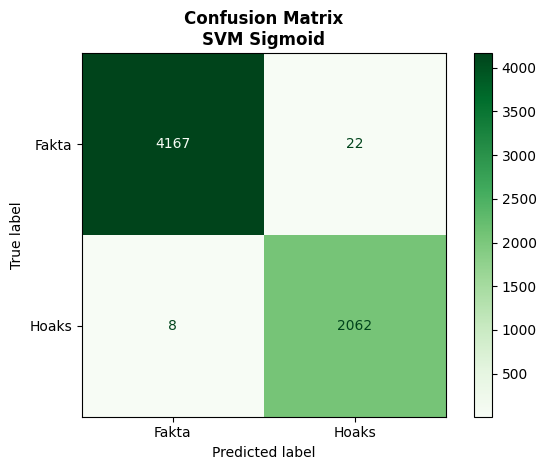

In [ ]:
cm_sigmoid = confusion_matrix(
    y_test,
    y_pred_sigmoid
)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_sigmoid,
    display_labels=['Fakta', 'Hoaks']
)

disp.plot(
    cmap='Greens',
    values_format='d'
)

plt.title(
    'Confusion Matrix\nSVM Sigmoid',
    fontweight='bold'
)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    'confusion_matrix_svm_sigmoid.png',
    dpi=150
)

plt.show()